# EDA VR Biometric Authentication

Korpus: 41 osób, 3 urządzenia (Quest, Vive, Cosmos), 2 dni, 10 rzutów na sesję.
Plik ma shape `(41, 10, 135, 21)`.

## 0. Konfiguracja

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## 1. Wczytanie danych

In [2]:
data_dir = Path.cwd().parent / "Dataset" / "MotionsNumpy"

sessions = {}

for path in data_dir.glob("*.npy"):
    name = path.stem
    sessions[name] = np.load(path)

print(sessions.keys())

dict_keys(['Cosmos1', 'Cosmos2', 'Quest1', 'Quest2', 'Vive1', 'Vive2'])


## 2. Podstawowa charakterystyka

In [3]:
import pandas as pd

rows = []

for name, arr in sessions.items():
    rows.append({
        "session": name,
        "device": name[:-1],
        "day": int(name[-1]),
        "subjects": arr.shape[0],
        "throws": arr.shape[1],
        "timesteps": arr.shape[2],
        "features": arr.shape[3],
        "dtype": str(arr.dtype),
    })

summary = pd.DataFrame(rows).sort_values(["day", "device"]).reset_index(drop=True)
summary

,session,device,day,subjects,throws,timesteps,features,dtype
0,Cosmos1,Cosmos,1,41,10,135,21,float32
1,Quest1,Quest,1,41,10,135,21,float32
2,Vive1,Vive,1,41,10,135,21,float32
3,Cosmos2,Cosmos,2,41,10,135,21,float32
4,Quest2,Quest,2,41,10,135,21,float32
5,Vive2,Vive,2,41,10,135,21,float32


## 3. Kontrola poprawności

In [4]:
expected_sessions = {"Quest1", "Quest2", "Vive1", "Vive2", "Cosmos1", "Cosmos2"}
expected_shape = (41, 10, 135, 21)

checks = pd.DataFrame([
    {"check": "session files", "value": set(sessions) == expected_sessions},
    {"check": "shape", "value": all(arr.shape == expected_shape for arr in sessions.values())},
    {"check": "nan", "value": int(sum(np.isnan(arr).sum() for arr in sessions.values()))},
    {"check": "inf", "value": int(sum(np.isinf(arr).sum() for arr in sessions.values()))},
    {"check": "empty subject sessions", "value": int(sum((np.abs(arr).sum(axis=(1, 2, 3)) == 0).sum() for arr in sessions.values()))},
    {"check": "subjects", "value": sorted({arr.shape[0] for arr in sessions.values()})},
    {"check": "throws", "value": sorted({arr.shape[1] for arr in sessions.values()})},
    {"check": "timesteps", "value": sorted({arr.shape[2] for arr in sessions.values()})},
    {"check": "features", "value": sorted({arr.shape[3] for arr in sessions.values()})},
])

checks

,check,value
0,session files,True
1,shape,True
2,nan,0
3,inf,0
4,empty subject sessions,0
5,subjects,[41]
6,throws,[10]
7,timesteps,[135]
8,features,[21]


In [7]:
import seaborn as sns

fig_dir = Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

## 4. Opis cech

21 kanałów to 3 urządzenia × 7 cech. Kolejność grup: prawy kontroler, headset, lewy kontroler.
Każda grupa ma pozycję xyz, kąty Eulera xyz i trigger. W modelach wykorzystywane jest 18 kanałów pozycji i rotacji.

In [6]:
feature_names = ["pos_x", "pos_y", "pos_z", "rot_x", "rot_y", "rot_z", "trigger"]
feature_groups = [("right_controller", 0), ("headset", 7), ("left_controller", 14)]

feature_table = pd.DataFrame([
    {"group": group, "channel": base + offset, "feature": feature}
    for group, base in feature_groups
    for offset, feature in enumerate(feature_names)
])

feature_table["used"] = feature_table["feature"] != "trigger"
channel_labels = [
    f"{row.group}_{row.feature}"
    for row in feature_table.itertuples()
]
feature_table

,group,channel,feature,used
0,right_controller,0,pos_x,True
1,right_controller,1,pos_y,True
2,right_controller,2,pos_z,True
3,right_controller,3,rot_x,True
4,right_controller,4,rot_y,True
5,right_controller,5,rot_z,True
6,right_controller,6,trigger,False
7,headset,7,pos_x,True
8,headset,8,pos_y,True
9,headset,9,pos_z,True


## 5. Rozkład klas

In [7]:
samples_per_session = []

for name, arr in sessions.items():
    for subject in range(arr.shape[0]):
        samples_per_session.append({
            "session": name,
            "device": name[:-1],
            "day": int(name[-1]),
            "subject": subject,
            "samples": arr.shape[1],
        })

samples_per_session = pd.DataFrame(samples_per_session)
subject_day = samples_per_session.groupby(["subject", "day"], as_index=False)["samples"].sum()
device_day = samples_per_session.groupby(["device", "day"], as_index=False)["samples"].sum()

print("Liczba próbek na osobę i dzień:")
print(subject_day["samples"].value_counts().to_string())
print()
print("Liczba próbek na urządzenie i dzień:")
device_day

Liczba próbek na osobę i dzień:
samples
30    82

Liczba próbek na urządzenie i dzień:


,device,day,samples
0,Cosmos,1,410
1,Cosmos,2,410
2,Quest,1,410
3,Quest,2,410
4,Vive,1,410
5,Vive,2,410


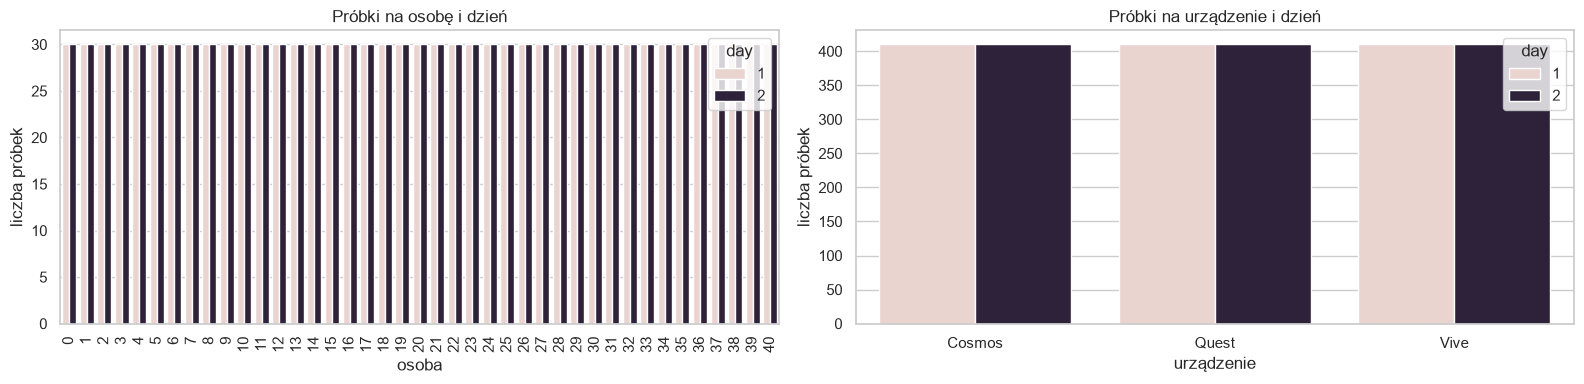

In [8]:
plot_subject_day = subject_day.assign(subject=subject_day["subject"].astype(str))

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

sns.barplot(data=plot_subject_day, x="subject", y="samples", hue="day", ax=axes[0])
axes[0].set_title("Próbki na osobę i dzień")
axes[0].set_xlabel("osoba")
axes[0].set_ylabel("liczba próbek")
axes[0].tick_params(axis="x", rotation=90)

sns.barplot(data=device_day, x="device", y="samples", hue="day", ax=axes[1])
axes[1].set_title("Próbki na urządzenie i dzień")
axes[1].set_xlabel("urządzenie")
axes[1].set_ylabel("liczba próbek")

plt.tight_layout()
plt.savefig(fig_dir / "rozklad_klas.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Jakość danych

In [9]:
channel_stats = []

for channel in range(21):
    values = np.concatenate([arr[..., channel].ravel() for arr in sessions.values()])
    channel_stats.append({
        "channel": channel,
        "label": channel_labels[channel],
        "mean": float(values.mean()),
        "std": float(values.std()),
        "min": float(values.min()),
        "p05": float(np.percentile(values, 5)),
        "p50": float(np.percentile(values, 50)),
        "p95": float(np.percentile(values, 95)),
        "max": float(values.max()),
        "zero_fraction": float((values == 0).mean()),
        "nan": int(np.isnan(values).sum()),
        "inf": int(np.isinf(values).sum()),
    })

channel_stats = pd.DataFrame(channel_stats)
channel_stats

,channel,label,mean,std,min,p05,p50,p95,max,zero_fraction,nan,inf
0,0,right_controller_pos_x,-0.683146,0.416087,-10.564087,-1.236319,-0.747286,0.064738,1.671882,0.000000,0,0
1,1,right_controller_pos_y,1.687561,0.382474,-4.658036,1.194321,1.620735,2.322669,3.310522,0.000000,0,0
2,2,right_controller_pos_z,0.093661,0.192354,-2.788888,-0.233051,0.089414,0.395621,4.177142,0.000000,0,0
3,3,right_controller_rot_x,-0.572143,1.800043,-3.141587,-2.823488,-1.137821,2.750117,3.141550,0.000000,0,0
4,4,right_controller_rot_y,-0.981079,0.520337,-1.570024,-1.486894,-1.151346,0.128707,1.557063,0.000000,0,0
5,5,right_controller_rot_z,0.101990,1.833689,-3.141585,-2.832771,0.018821,2.892510,3.141589,0.000000,0,0
6,6,right_controller_trigger,0.476631,0.496774,0.000000,0.000000,0.011765,1.000000,1.000000,0.497284,0,0
7,7,headset_pos_x,-0.486770,0.168433,-1.154045,-0.753524,-0.490321,-0.203782,0.391514,0.000000,0,0
8,8,headset_pos_y,2.066721,0.135200,1.607676,1.829327,2.074868,2.281953,2.447160,0.000000,0,0
9,9,headset_pos_z,-0.077595,0.085695,-0.544141,-0.232091,-0.067099,0.043509,0.221442,0.000000,0,0


In [10]:
constant_channels = channel_stats.loc[channel_stats["std"] == 0, "channel"].tolist()

trigger_summary = pd.DataFrame([
    {
        "session": name,
        "right_trigger_nonzero": int((arr[..., 6] != 0).sum()),
        "headset_trigger_nonzero": int((arr[..., 13] != 0).sum()),
        "left_trigger_nonzero": int((arr[..., 20] != 0).sum()),
    }
    for name, arr in sessions.items()
])

print("Stałe kanały:", constant_channels)
print("NaN:", int(channel_stats["nan"].sum()))
print("Inf:", int(channel_stats["inf"].sum()))
print()

trigger_summary

Stałe kanały: [13]
NaN: 0
Inf: 0



,session,right_trigger_nonzero,headset_trigger_nonzero,left_trigger_nonzero
0,Cosmos1,26121,0,35
1,Cosmos2,25837,0,8
2,Quest1,27626,0,0
3,Quest2,28202,0,130
4,Vive1,29872,0,6739
5,Vive2,29294,0,1358


In [11]:
outlier_rows = []

for name, arr in sessions.items():
    q1 = np.quantile(arr, 0.25, axis=(0, 1, 2))
    q3 = np.quantile(arr, 0.75, axis=(0, 1, 2))
    iqr = q3 - q1
    mask = (arr < q1 - 1.5 * iqr) | (arr > q3 + 1.5 * iqr)
    outlier_rows.append({"session": name, "outliers": int(mask.sum())})

outlier_counts = pd.DataFrame(outlier_rows)
outlier_counts

,session,outliers
0,Cosmos1,14954
1,Cosmos2,13301
2,Quest1,13770
3,Quest2,15004
4,Vive1,26634
5,Vive2,24603


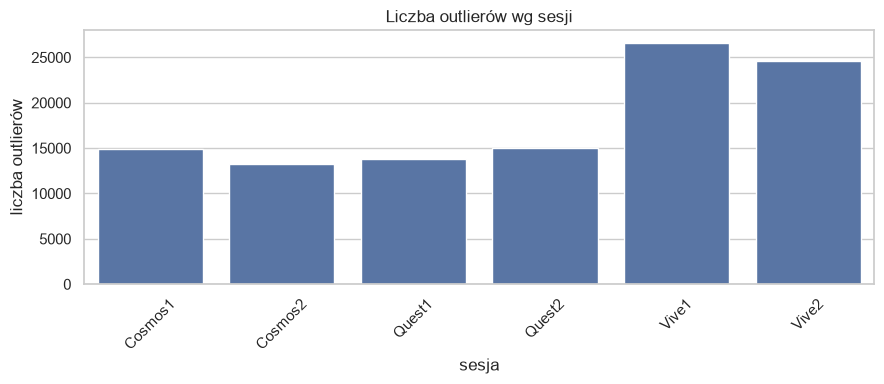

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))

sns.barplot(data=outlier_counts, x="session", y="outliers", ax=ax)
ax.set_title("Liczba outlierów wg sesji")
ax.set_xlabel("sesja")
ax.set_ylabel("liczba outlierów")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(fig_dir / "outliery_sesje.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Statystyki opisowe

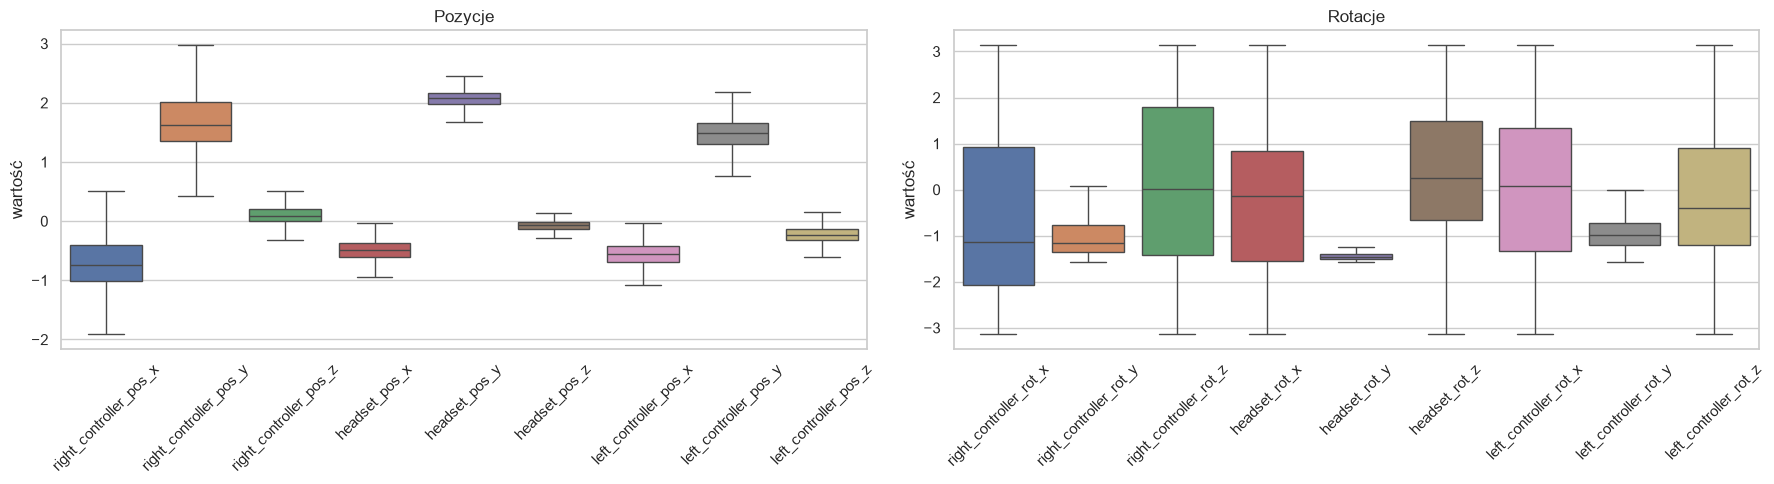

In [13]:
all_values = np.concatenate([arr.reshape(-1, 21) for arr in sessions.values()], axis=0)
value_table = pd.DataFrame(all_values, columns=channel_labels)

pos_columns = [label for label in channel_labels if "_pos_" in label]
rot_columns = [label for label in channel_labels if "_rot_" in label]

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.boxplot(data=value_table[pos_columns], ax=axes[0], showfliers=False)
axes[0].set_title("Pozycje")
axes[0].set_ylabel("wartość")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=value_table[rot_columns], ax=axes[1], showfliers=False)
axes[1].set_title("Rotacje")
axes[1].set_ylabel("wartość")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(fig_dir / "statystyki_kanalow.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Trajektorie

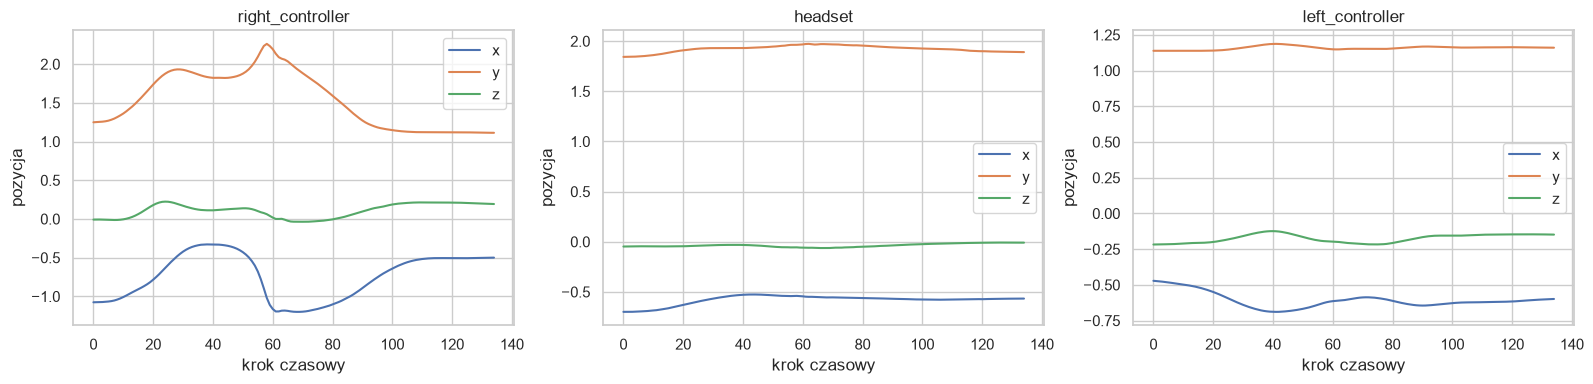

In [14]:
arr = sessions["Quest1"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)

for ax, (group, base) in zip(axes, feature_groups):
    for label, offset in zip(["x", "y", "z"], range(3)):
        ax.plot(arr[0, 0, :, base + offset], label=label)
    ax.set_title(group)
    ax.set_xlabel("krok czasowy")
    ax.set_ylabel("pozycja")
    ax.legend()

plt.tight_layout()
plt.savefig(fig_dir / "trajektorie_pozycji.png", dpi=150, bbox_inches="tight")
plt.show()

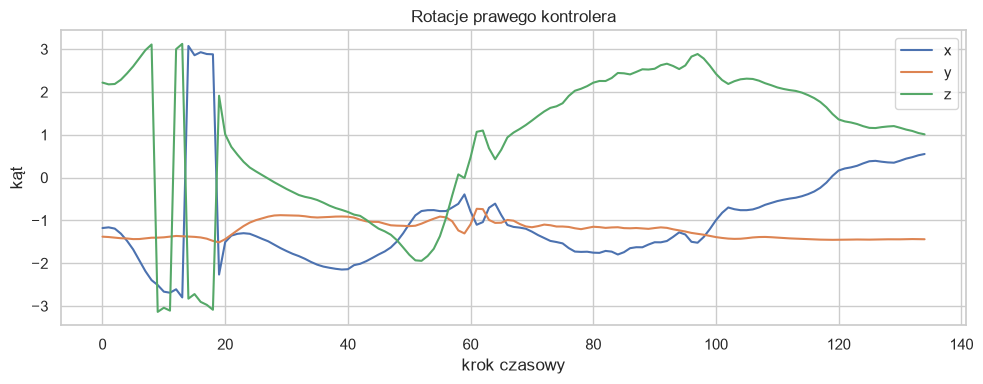

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))

for label, offset in zip(["x", "y", "z"], range(3, 6)):
    ax.plot(arr[0, 0, :, offset], label=label)

ax.set_title("Rotacje prawego kontrolera")
ax.set_xlabel("krok czasowy")
ax.set_ylabel("kąt")
ax.legend()

plt.tight_layout()
plt.savefig(fig_dir / "trajektorie_rotacji.png", dpi=150, bbox_inches="tight")
plt.show()

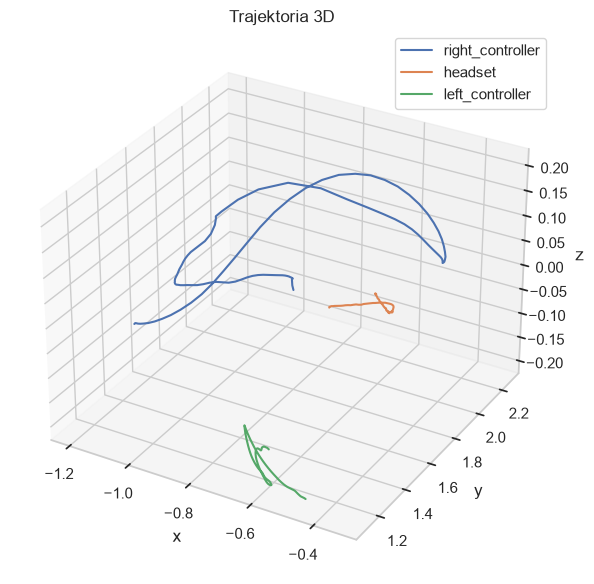

In [16]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

for group, base in feature_groups:
    ax.plot(
        arr[0, 0, :, base],
        arr[0, 0, :, base + 1],
        arr[0, 0, :, base + 2],
        label=group,
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Trajektoria 3D")
ax.legend()

plt.tight_layout()
plt.savefig(fig_dir / "trajektoria_3d.png", dpi=150, bbox_inches="tight")
plt.show()

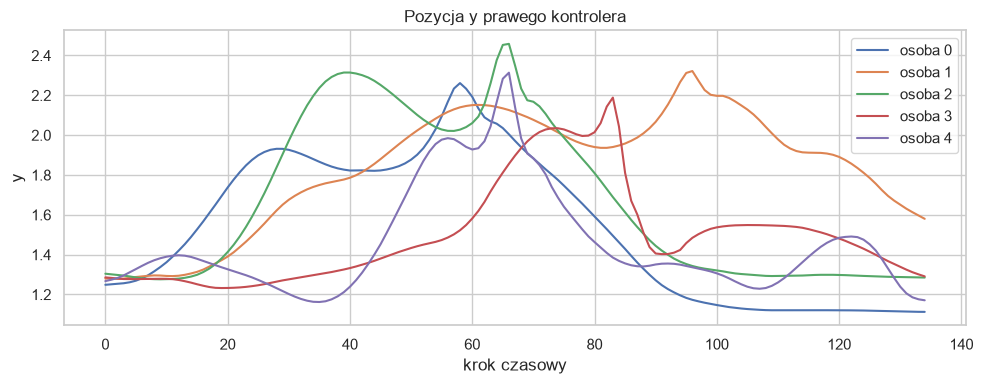

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))

for subject in range(5):
    ax.plot(sessions["Quest1"][subject, 0, :, 1], label=f"osoba {subject}")

ax.set_title("Pozycja y prawego kontrolera")
ax.set_xlabel("krok czasowy")
ax.set_ylabel("y")
ax.legend()

plt.tight_layout()
plt.savefig(fig_dir / "zmiennosc_miedzyosobnicza.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Porównanie dnia 1 i dnia 2

In [18]:
day_stats = []

for day in [1, 2]:
    values = np.concatenate([
        arr.reshape(-1, 21)
        for name, arr in sessions.items()
        if int(name[-1]) == day
    ], axis=0)
    for channel in range(21):
        day_stats.append({
            "day": day,
            "channel": channel,
            "mean": float(values[:, channel].mean()),
            "std": float(values[:, channel].std()),
        })

day_stats = pd.DataFrame(day_stats)
means = day_stats.pivot(index="channel", columns="day", values="mean")
stds = day_stats.pivot(index="channel", columns="day", values="std")

day_comparison = pd.DataFrame({
    "label": channel_labels,
    "mean_day1": means[1].values,
    "mean_day2": means[2].values,
    "std_day1": stds[1].values,
    "std_day2": stds[2].values,
})
day_comparison["mean_shift"] = (
    (day_comparison["mean_day2"] - day_comparison["mean_day1"])
    / day_comparison["std_day1"].replace(0, np.nan)
)
day_comparison

,label,mean_day1,mean_day2,std_day1,std_day2,mean_shift
0,right_controller_pos_x,-0.687356,-0.678935,0.411818,0.420271,0.020449
1,right_controller_pos_y,1.694930,1.680192,0.374325,0.390313,-0.039371
2,right_controller_pos_z,0.090046,0.097276,0.186873,0.197616,0.038687
3,right_controller_rot_x,-0.549331,-0.594954,1.800356,1.799441,-0.025341
4,right_controller_rot_y,-0.989207,-0.972951,0.513614,0.526849,0.031650
5,right_controller_rot_z,0.082374,0.121606,1.829463,1.837696,0.021445
6,right_controller_trigger,0.477322,0.475941,0.496804,0.496744,-0.002779
7,headset_pos_x,-0.490164,-0.483376,0.171419,0.165323,0.039598
8,headset_pos_y,2.068857,2.064585,0.133555,0.136791,-0.031987
9,headset_pos_z,-0.080738,-0.074451,0.087654,0.083572,0.071725


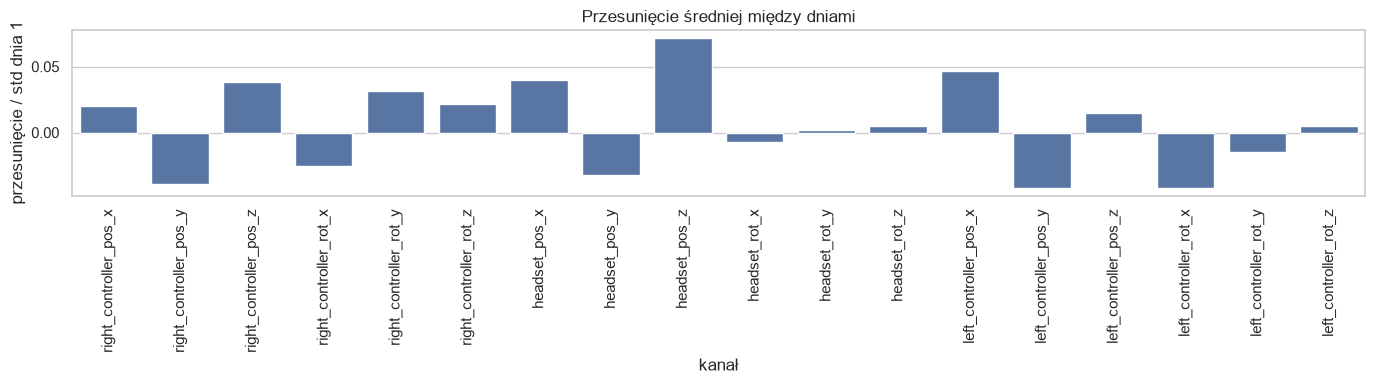

In [19]:
plot_data = day_comparison[day_comparison["label"].str.contains("pos|rot")]

fig, ax = plt.subplots(figsize=(14, 4))

sns.barplot(data=plot_data, x="label", y="mean_shift", ax=ax)
ax.set_title("Przesunięcie średniej między dniami")
ax.set_xlabel("kanał")
ax.set_ylabel("przesunięcie / std dnia 1")
ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.savefig(fig_dir / "przesuniecie_dni.png", dpi=150, bbox_inches="tight")
plt.show()

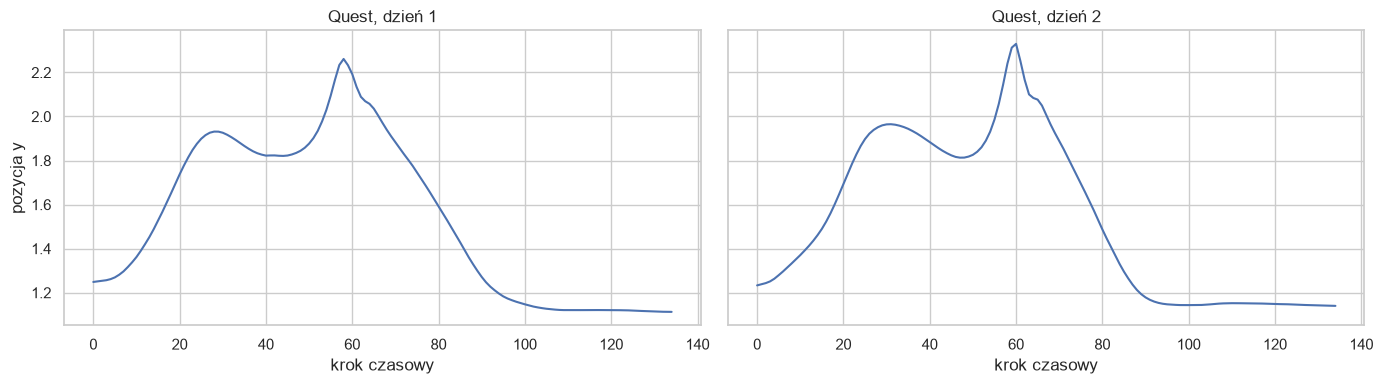

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, day in zip(axes, [1, 2]):
    arr_day = sessions[f"Quest{day}"]
    ax.plot(arr_day[0, 0, :, 1])
    ax.set_title(f"Quest, dzień {day}")
    ax.set_xlabel("krok czasowy")

axes[0].set_ylabel("pozycja y")
plt.tight_layout()
plt.savefig(fig_dir / "trajektorie_dzien1_dzien2.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Porównanie urządzeń

In [21]:
device_stats = []

for device in ["Quest", "Vive", "Cosmos"]:
    values = np.concatenate([
        arr.reshape(-1, 21)
        for name, arr in sessions.items()
        if name[:-1] == device
    ], axis=0)
    for channel in range(21):
        device_stats.append({
            "device": device,
            "channel": channel,
            "mean": float(values[:, channel].mean()),
            "std": float(values[:, channel].std()),
            "min": float(values[:, channel].min()),
            "max": float(values[:, channel].max()),
        })

device_stats = pd.DataFrame(device_stats)
device_std = device_stats.pivot(index="channel", columns="device", values="std")
device_std.index = channel_labels
device_std

device,Cosmos,Quest,Vive
right_controller_pos_x,0.432628,0.413855,0.400939
right_controller_pos_y,0.368057,0.364353,0.406582
right_controller_pos_z,0.190990,0.187650,0.197620
right_controller_rot_x,1.844329,1.814657,1.695611
right_controller_rot_y,0.506851,0.525383,0.528349
right_controller_rot_z,1.748898,1.908840,1.786279
right_controller_trigger,0.497477,0.499054,0.492876
headset_pos_x,0.154940,0.187113,0.161040
headset_pos_y,0.110826,0.107533,0.106518
headset_pos_z,0.088867,0.085698,0.081573


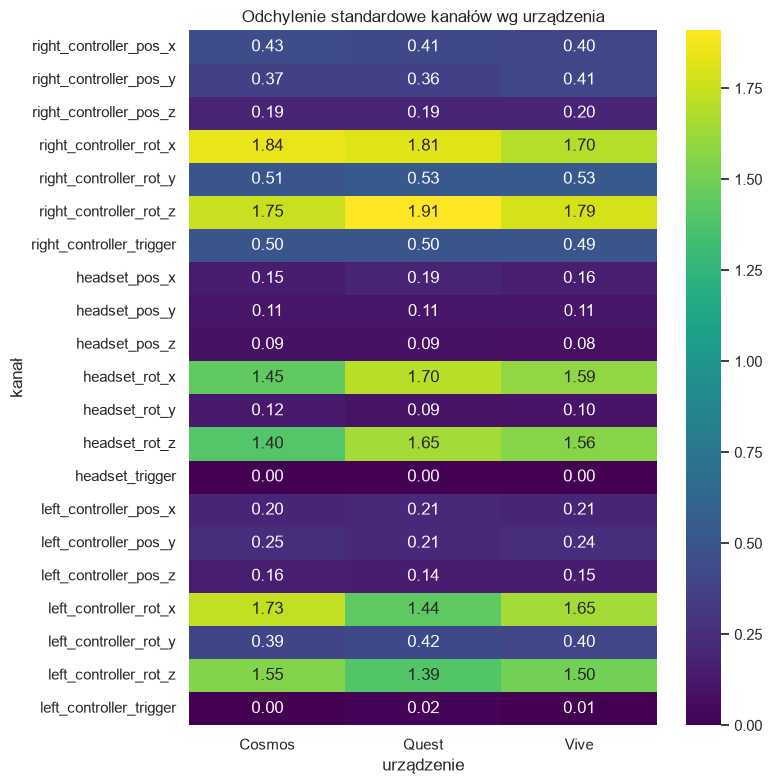

In [22]:
fig, ax = plt.subplots(figsize=(8, 8))

sns.heatmap(device_std, annot=True, fmt=".2f", cmap="viridis", ax=ax)
ax.set_title("Odchylenie standardowe kanałów wg urządzenia")
ax.set_xlabel("urządzenie")
ax.set_ylabel("kanał")

plt.tight_layout()
plt.savefig(fig_dir / "odchylenia_urzadzenia.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Wnioski

- Zbiór jest kompletny: brak NaN, brak inf, brak pustych sesji.
- W każdym pliku jest 41 osób, 10 rzutów, 135 kroków czasowych i 21 cech.
- Na dzień przypada 1230 próbek, łącznie 2460. Klasy są idealnie zbalansowane: 30 próbek na osobę i dzień oraz 410 próbek na urządzenie i dzień.
- Realnie informacyjnych jest 18 z 21 kanałów. Trigger headsetu jest zawsze zerowy, a trigger lewego kontrolera jest prawie zawsze zerowy.
- Trigger prawego kontrolera przyjmuje wartości 0-1 i nie jest używany w modelach.
- W danych występują outliery; najwięcej w sesjach Vive1 i Vive2, a skrajne wartości pozycji w Quest2.
- Kąty Eulera mieszczą się w zakresie około `[-π, π]`.
- Rozkłady i wariancje cech różnią się między urządzeniami; średnie między dniami są zbliżone, ale zmieniają się odchylenia i liczba outlierów.
- Walidacja z dnia 1 jest łatwiejsza niż test z dnia 2. Właściwą metryką cross-day jest wynik na dniu 2.
- Do modeli należy używać 18 kanałów pozycji i rotacji, z normalizacją dopasowaną na treningu.